# Chance level C vs IP: minimum epochs and time×electrode map

**Three questions:**
1. How many epochs are needed (approx.) to overcome the chance level in C vs IP?
2. For each electrode, from what moment is the chance level exceeded?
3. At group level, where and when can we say that accuracy exceeds chance?

**Methodology:**
- Surrogate by tag permutation, **per subject × electrode × time window**.
- ΔAcc = Acc_actual(t) − Acc_chance(t)
- Group contrast: paired t-test one-tailed vectorized + FDR per cell (channel, t).
- Parallelism: `joblib.Parallel` (N_JOBS) on subjects.
- Intermediate tensors are saved to disk to avoid recalculation if the kernel crashes.


In [1]:
import warnings
from pathlib import Path
from scipy.signal import hilbert
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import numpy as np
import pandas as pd
from joblib import Parallel, delayed, cpu_count
from scipy.stats import ttest_rel
from scipy.signal import hilbert
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, average_precision_score
import sys

# Add src directory to path so we can import br_analysis
src_path = Path(r"c:\Users\nils\Documents\Universitat\TFG\src")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from br_analysis import detect_project_paths, get_task_config, get_epochs_grid, COMMON_BAND_RANGES
from br_analysis.experiments import (
    ChanceLevelExperiment,
    TimeWindowGrid,
    ExperimentSettings,
    choose_n_splits,
    temporal_stratified_splits,
)
from br_analysis.models import LogRegModelFactory
from br_analysis.features import HilbertMeanEnvelope

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    drive.mount("/content/drive")

paths = detect_project_paths("c_vs_i", in_colab=IN_COLAB)
PROJECT_DIR = paths.project_dir
BASE_DIR = paths.project_dir
DATA_DIR = paths.data_dir
ANALYSIS_ROOT = paths.analysis_root
ANALYSIS_DIR = paths.analysis_dir
CACHE_DIR = paths.cache_dir
TABLES_DIR = paths.tables_dir
FIGURES_DIR = paths.figures_dir
DATA_FILES = paths.data_files

## Configuration

In [2]:
TASK_TAG = "c_vs_i_FCz_theta_Oz_alpha"
RECALCULAR_CHANCE_LEVEL = False
ANALYSIS_WINDOW = (0.5, 1.0)

# Compact definition: (electrode, strip)
TARGET_BAND_CHANNELS = (
    ("FCz", "theta"),
    ("Oz", "alpha"),
)
BAND_RANGES = COMMON_BAND_RANGES
CHANNEL_MODE = [f"{ch}-{band}" for ch, band in TARGET_BAND_CHANNELS]

# Centralized task config and epochs grid
TASK = get_task_config("c_vs_ip", ANALYSIS_ROOT, name="c_vs_i", analysis_window=ANALYSIS_WINDOW)
EPOCHS_GRID = get_epochs_grid("c_vs_ip")

# Map of conditions, subjects, etc. from the centralized configuration
COND_EVENTS_CODES = TASK.event_codes
COND_EVENTS = TASK.cond_events
SELECTED_SUBJECTS_CSV = TASK.selected_subjects_csv
MAX_SUBJECTS = TASK.max_subjects
UNDERSAMPLE_CLASSES = TASK.undersample_classes

# Output directories
RESULTS_DIR = ANALYSIS_DIR
CACHE_EPOCHS_DIR = CACHE_DIR
CACHE_MAP_FILE = CACHE_DIR / f"map_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else 'all'}.npz"
EPOCHS_CSV = TABLES_DIR / f"epochs_grid_{TASK_TAG}.csv"
ONSET_CSV = TABLES_DIR / f"onset_summary_{TASK_TAG}.csv"

# Time×electrode map
MAP_WINDOW_SEC = 0.500  # time window width (s)
MAP_STEP_SEC = 0.1  # pas (s)
MAP_CV_MAX_SPLITS = 5  # maximum CV folds

# Surrogate
N_PERM_SURROGATE = 100

# Grid epochs (repeated subsampling)
N_REPEATS_EPOCHS = 15
N_JOBS = 6

RANDOM_SEED = TASK.random_seed

print(f"BASE_DIR: {BASE_DIR}")
print(f"ANALYSIS_ROOT: {ANALYSIS_ROOT}")
print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"CACHE_DIR: {CACHE_DIR}")
print(f"TABLES_DIR: {TABLES_DIR}")
print(f"FIGURES_DIR: {FIGURES_DIR}")
print(f"SELECTED_SUBJECTS_CSV: {SELECTED_SUBJECTS_CSV}")
print(f"CACHE_MAP_FILE: {CACHE_MAP_FILE}")
print(f"TARGET_BAND_CHANNELS: {TARGET_BAND_CHANNELS}")
print(f"BAND_RANGES: {BAND_RANGES}")
print(f"COND_EVENTS_CODES: {COND_EVENTS_CODES}")
print(f"COND_EVENTS (tags): {COND_EVENTS}")

# Unified experiment settings and runner
settings = ExperimentSettings(
    task_tag=TASK_TAG,
    random_seed=RANDOM_SEED,
    map_cv_max_splits=MAP_CV_MAX_SPLITS,
    n_perm_surrogate=N_PERM_SURROGATE,
    epochs_grid=EPOCHS_GRID,
    n_repeats_epochs=N_REPEATS_EPOCHS,
    n_jobs=N_JOBS,
    recalculate=RECALCULAR_CHANCE_LEVEL,
)
model_factory = LogRegModelFactory(random_seed=RANDOM_SEED)
feature_extractor = HilbertMeanEnvelope()
experiment = ChanceLevelExperiment(
    settings=settings,
    model_factory=model_factory,
    feature_extractor=feature_extractor,
)

BASE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
ANALYSIS_ROOT: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
RESULTS_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i
CACHE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache
TABLES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\tables
FIGURES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\figures
SELECTED_SUBJECTS_CSV: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\exploration\tables\subjectes_seleccionats.csv
CACHE_MAP_FILE: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\map_c_vs_i_FCz_theta_Oz_alpha_sub24.npz
TARGET_BAND_CHANNELS: (('FCz', 'theta'), ('Oz', 'alpha'))
BAND

## 1. Loading data

In [3]:
def load_chance_epochs():
    """Load the first MAX_SUBJECTS of the selection CSV and build derived channels."""

    cache_file = CACHE_DIR / f"cache_epochs_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else 'all'}.joblib"
    if cache_file.exists():
        print(f"Loading cached epochs from {cache_file}...")
        return joblib.load(cache_file)
    df_sel = pd.read_csv(SELECTED_SUBJECTS_CSV)

    subject_ids = df_sel["subject"].dropna().astype(str).tolist()
    subject_ids = list(dict.fromkeys(subject_ids))  # deduplication preserving order
    if MAX_SUBJECTS is not None:
        subject_ids = subject_ids[:MAX_SUBJECTS]
    print(f"Selected subjects to load: {len(subject_ids)}")

    fif_by_subject = {p.stem: p for p in DATA_FILES}
    derived_ch_names = [f"{ch_name}-{band}" for ch_name, band in TARGET_BAND_CHANNELS]

    X_blocks, y_blocks, subj_blocks = [], [], []
    skipped = []

    for subj_name in subject_ids:
        fif_path = fif_by_subject.get(subj_name)
        if fif_path is None:
            skipped.append(f"{subj_name}: fitxer .fif no trobat")
            continue

        ep = mne.read_epochs(fif_path, preload=False)
        ep.load_data()

        # Some files come with zero EEG units; we normalize to volts before changing the type.
        for ch_idx, ch_name in enumerate(ep.ch_names):
            if ep.info["chs"][ch_idx]["unit"] == 0:
                ep.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ep.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        # Preserves only EEG channels; if the file does not have EEG types, force them to EEG.
        ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")
        ep = ep.copy().pick(mne.pick_types(ep.info, eeg=True))

        # The actual selection is made by the codes of 01; tags are kept for reference only.
        c_codes = COND_EVENTS_CODES[TASK.class_0]
        ip_codes = COND_EVENTS_CODES[TASK.class_1]
        events = ep.events[:, 2]
        c_mask = np.isin(events, c_codes)
        ip_mask = np.isin(events, ip_codes)
        if not c_mask.any() or not ip_mask.any():
            skipped.append(f"{fif_path.name}: missing required codes (C={int(c_mask.sum())}, IP={int(ip_mask.sum())})")
            continue
        ep = ep[c_mask | ip_mask].copy().crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])

        events = ep.events[:, 2]
        y_s = np.where(np.isin(events, c_codes), 0, 1).astype(np.int8)

        n_c, n_i = int((y_s == 0).sum()), int((y_s == 1).sum())
        if min(n_c, n_i) == 0:
            skipped.append(f"{fif_path.name}: classe buida (C={n_c}, IP={n_i})")
            continue

        if UNDERSAMPLE_CLASSES:
            n_min = min(n_c, n_i)
            idx_c = np.where(y_s == 0)[0]
            idx_i = np.where(y_s == 1)[0]
            rng = np.random.default_rng(RANDOM_SEED + sum(bytearray(subj_name.encode("utf-8"))))
            keep_idx = np.concatenate(
                [
                    rng.choice(idx_c, n_min, replace=False),
                    rng.choice(idx_i, n_min, replace=False),
                ]
            )
            rng.shuffle(keep_idx)
            ep = ep[keep_idx]
            y_s = y_s[keep_idx]

        band_arrays = []
        missing_specs = []
        for ch_name, band in TARGET_BAND_CHANNELS:
            if ch_name not in ep.ch_names:
                missing_specs.append(f"{ch_name}-{band}")
                continue
            if band not in BAND_RANGES:
                raise ValueError(f"Banda no suportada: {band}. Defineix-la a BAND_RANGES.")

            l_freq, h_freq = BAND_RANGES[band]
            ep_band = ep.copy().pick([ch_name])
            ep_band._data = np.ascontiguousarray(ep_band._data)
            ep_band.filter(
                l_freq=l_freq,
                h_freq=h_freq,
                method="fir",
                fir_design="firwin",
                phase="zero-double",
                verbose=False,
            )
            x_band = ep_band.get_data()[:, 0, :].astype(np.float32)
            band_arrays.append(x_band)

        if missing_specs or len(band_arrays) != len(TARGET_BAND_CHANNELS):
            skipped.append(f"{fif_path.name}: missing required specifications ({', '.join(missing_specs)})")
            continue

        X_s = np.stack(band_arrays, axis=1)  # (trials, n_specs, times)
        X_blocks.append(X_s)
        y_blocks.append(y_s)
        subj_blocks.extend([subj_name] * len(y_s))

    X = np.concatenate(X_blocks, axis=0)
    y = np.concatenate(y_blocks, axis=0)
    subj_list = np.array(subj_blocks, dtype=object)
    ch_names = derived_ch_names
    times = np.array(ep.times, dtype=np.float32)

    print(f"Total Samples: {len(y)} | C={(y==0).sum()} | IP={(y==1).sum()}")
    print(f"Loaded subjects: {len(np.unique(subj_list))} | Derivative channels: {ch_names} | Time: {len(times)}")
    if skipped:
        print("Omesos:")
        for m in skipped:
            print(f"  {m}")

    ret_val = (X, y, subj_list, ch_names, times)
    joblib.dump(ret_val, cache_file, compress=3)
    print(f"Saved loaded epochs to cache: {cache_file}")
    return X, y, subj_list, ch_names, times


X, y, subj_list, ch_names, times = load_chance_epochs()

Loading cached epochs from H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\cache_epochs_c_vs_i_FCz_theta_Oz_alpha_sub24.joblib...


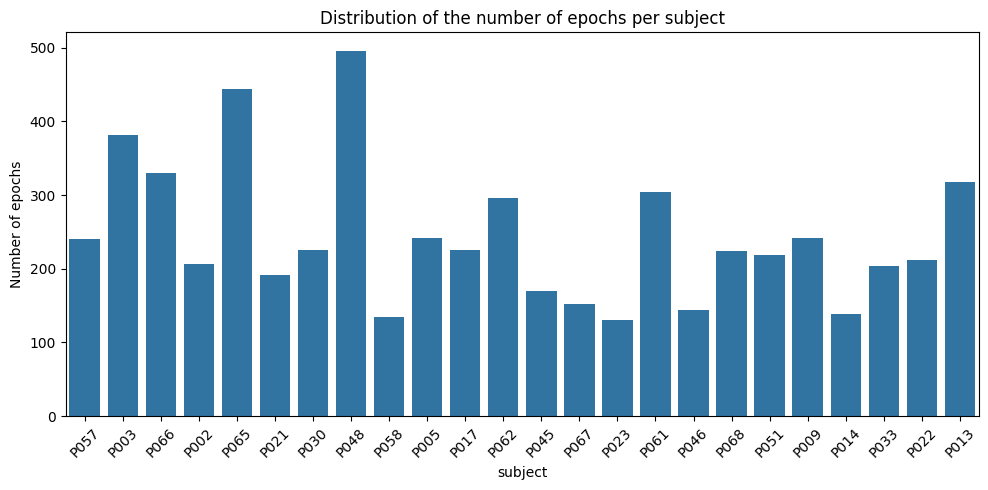

In [43]:
# Histogram of number of epochs per subject
plt.figure(figsize=(10, 5))
sns.countplot(x=subj_list)
plt.xticks(rotation=45)
plt.xlabel("subject")
plt.ylabel("Number of epochs")
plt.title("Distribution of the number of epochs per subject")
plt.tight_layout()
plt.show()

## 2. Pipeline Design and Validation Method

To validate whether our classification results are real or the result of chance (chance level), we implement a centralized rigorous pipeline in the `ChanceLevelExperiment` class of `br_analysis.experiments`. This ensures that all classical ranking analyzes follow the same logic and ensures consistency of results.

This pipeline is structured in two experiments:
1. **Grid of Epochs (Epochs Grid)**: To study how many trials the model needs to obtain a performance statistically superior to chance.
2. **Time-Electrode Map**: To identify in which time windows and in which channels or frequency bands the relevant information is concentrated.

```mermaid
graph TD
    A[Epoch Data Loading by Subject] --> B[Epoch Balanced Subsampling]
    B --> C[Temporal Stratified Cross-Validation]
    C --> D[Feature Extraction: Hilbert Envelope]
    D --> E[Classifier Training: Logistic Regression]
    E --> F[Real Accuracy Calculation]
    E --> G[Generating Surrogate Distributions via Label Permutation]
    F --> H[Comparison: Accuracy Delta and Q95 Threshold]
    G --> H
    H --> I[Group Analysis: Paired t-test and Hit-rate]
```

### Key Components of the Pipeline

1. **Balanced Subsampling (`balanced_sample`)**:
   - Before training the model on a subset of epochs (from 20 to 190, in steps of 10), a random but strictly balanced sampling is performed (equal number of epochs from each class, e.g. IM and IP or C and I).
   - This sets the a priori probability of each class at exactly 50%, eliminating biases that could alter the accuracy.

2. **Temporal Stratified Cross Validation (`temporal_stratified_splits`)**:
   - EEG-type signals have a strong temporal dependence. To prevent information from the future leaking into the past (*data leakage*), we use a *forward-chaining* cross-validation. Test sets are always later in time than train sets.
   - The number of partitions (folds) is dynamically adapted per subject based on the least frequent class in the sample (`choose_n_splits(y_s, max_splits=5)`). In case of highly asymmetric distributions or extreme random permutations where the net temporal match fails, the function has fallbacks to a randomized 2-fold.

3. **Extraction of Characteristics and Classification**:
   - **Features**: The mean envelope of the signal is extracted using the Hilbert transform (`HilbertMeanEnvelope`) for the selected time window of each channel.
   - **Classifier**: A Logistic Regression (`LogRegModelFactory`) is trained and evaluated.

4. **Chance Level and Surrogate Distributions**:
   - For each time setting or number of epochs, we calculate:
     - **Accuracy Real (`acc_real_mean`)**: Average of the cross-validation accuracies with the real labels.
     - **Distribution of Chance / Surrogates**: Real labels are shuffled randomly $N$ times (default 100). For each permutation, the entire cross-validation process is repeated.
     - **Q95 Threshold (`acc_chance_q95`)**: The 95th percentile of the accuracies of the surrogate distribution. If the actual accuracy of the subject exceeds this threshold, we consider the classification to be statistically significant ($p < 0.05$).

5. **Group Statistical Analysis**:
   - To evaluate group-level significance for each cell (channel/band, time), we perform a **paired t-test** of the actual accuracy vs. the average chance of each subject.
   - A cell is considered **robust** if the t-test is significant ($p < 0.05$ from the upper tail) **and** the group *hit-rate* is $\ge 0.50$ (at least half of the subjects individually exceed their Q95 threshold).

## 3. Execution (parallel by subject)

In [58]:
subject_ids = pd.unique(subj_list).tolist()

CACHE_EPOCHS = CACHE_EPOCHS_DIR / (
    f"epochs_grid_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else str(len(subject_ids))}.csv"
)

print(
    f"Grid epochs — {len(subject_ids)} subj × {len(ch_names)} canals × "
    f"{len(EPOCHS_GRID)} punts × {N_REPEATS_EPOCHS} reps …"
)

df_epochs = experiment.run_epochs_grid(X, y, subj_list, ch_names, cache_file=CACHE_EPOCHS)

df_epochs.to_csv(EPOCHS_CSV, index=False)
print(f"Saved table: {EPOCHS_CSV}")
df_epochs.head(10)

Grid epochs — 24 subj × 2 canals × 8 punts × 15 reps …


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done   6 tasks      | elapsed: 31.8min
[Parallel(n_jobs=6)]: Done  18 out of  24 | elapsed: 73.1min remaining: 24.4min
[Parallel(n_jobs=6)]: Done  24 out of  24 | elapsed: 101.4min finished


Desat cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\epochs_grid_c_vs_i_FCz_theta_Oz_alpha_sub24.csv
Saved table: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\tables\epochs_grid_c_vs_i_FCz_theta_Oz_alpha.csv


,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P002,FCz-theta,20,0.511574,0.136346,0.509546,0.750000,0.002028,-0.238426
1,P002,FCz-theta,40,0.490952,0.102582,0.504373,0.662143,-0.013421,-0.171190
2,P002,FCz-theta,70,0.496869,0.037235,0.502035,0.606667,-0.005167,-0.109798
3,P002,FCz-theta,100,0.486618,0.045266,0.499904,0.601471,-0.013287,-0.114853
4,P002,FCz-theta,150,0.487467,0.034000,0.492800,0.568000,-0.005333,-0.080533
5,P002,FCz-theta,200,0.501937,0.028394,0.501067,0.555160,0.000870,-0.053223
6,P002,Oz-alpha,20,0.484444,0.100779,0.513472,0.734167,-0.029028,-0.249722
7,P002,Oz-alpha,40,0.545079,0.065750,0.495254,0.638095,0.049825,-0.093016
8,P002,Oz-alpha,70,0.532323,0.060037,0.504217,0.603106,0.028106,-0.070783
9,P002,Oz-alpha,100,0.509314,0.050073,0.499686,0.576471,0.009627,-0.067157


In [59]:
# Show df_epochs sorted by delta_acc_q95 descending
df_epochs_sorted = df_epochs.sort_values("delta_acc_q95", ascending=False).reset_index(drop=True)
display(df_epochs_sorted.head(10**6))

,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P057,Oz-alpha,200,0.670802,0.017557,0.497969,0.560980,0.172833,0.109822
1,P057,Oz-alpha,150,0.672000,0.028770,0.502160,0.568000,0.169840,0.104000
2,P057,Oz-alpha,100,0.663088,0.039966,0.497363,0.589743,0.165726,0.073346
3,P003,Oz-alpha,380,0.600556,0.003230,0.500454,0.544675,0.100101,0.055880
4,P017,Oz-alpha,200,0.615865,0.014313,0.501041,0.560080,0.114824,0.055784
...,...,...,...,...,...,...,...,...,...
279,P017,FCz-theta,20,0.472037,0.102106,0.501236,0.750000,-0.029199,-0.277963
280,P022,FCz-theta,20,0.449537,0.182601,0.500375,0.730208,-0.050838,-0.280671
281,P023,Oz-alpha,20,0.478889,0.131291,0.494829,0.766875,-0.015940,-0.287986
282,P046,FCz-theta,20,0.456852,0.080114,0.493616,0.750000,-0.036764,-0.293148


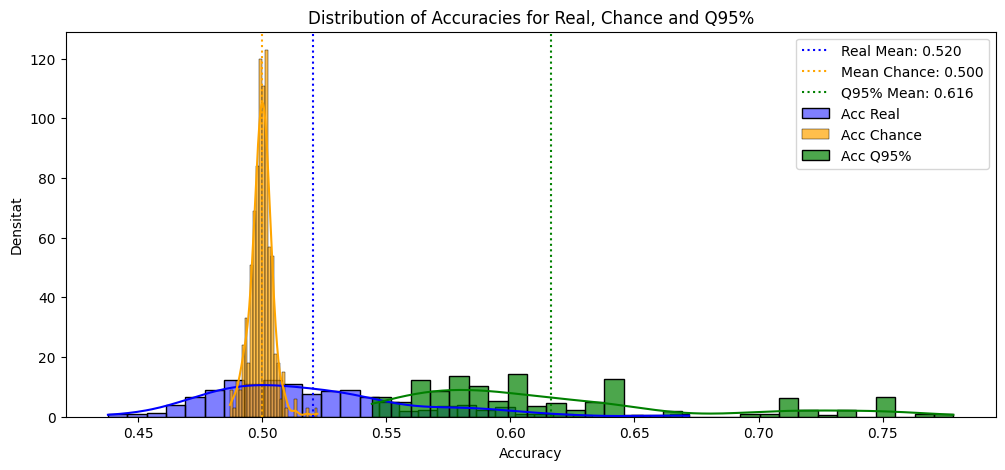

In [ ]:
# Histogram acc_real_mean, acc_chance_mean and acc_chance_q95 with seaborn
plt.figure(figsize=(12, 5))
sns.histplot(df_epochs, x="acc_real_mean", color="blue", label="Acc Real", kde=True, stat="density", bins=30)
sns.histplot(
    df_epochs, x="acc_chance_mean", color="orange", label="Acc Chance", kde=True, stat="density", bins=30, alpha=0.7
)
sns.histplot(
    df_epochs, x="acc_chance_q95", color="green", label="Acc Q95%", kde=True, stat="density", bins=30, alpha=0.7
)
plt.title("Distribution of Accuracies for Real, Chance and Q95%")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
# Show averages of the three groups
mean_real = df_epochs["acc_real_mean"].mean()
mean_chance = df_epochs["acc_chance_mean"].mean()
mean_q95 = df_epochs["acc_chance_q95"].mean()

plt.axvline(mean_real, color="blue", linestyle=":", label=f"Real Mean: {mean_real * 100:.1f}%")
plt.axvline(mean_chance, color="orange", linestyle=":", label=f"Mean Chance: {mean_chance * 100:.1f}%")
plt.axvline(mean_q95, color="green", linestyle=":", label=f"Q95% Mean: {mean_q95 * 100:.1f}%")
plt.legend()
plt.savefig(FIGURES_DIR / f"histogram_epochs_{TASK_TAG}.png")
plt.show()

## 4. Numeric summary epochs → accuracy

This cell leaves only the numerical summary of the grid.
All figures are centralized in section 7.

In [61]:
# Numeric summary of the epoch grid
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

df_surpass = df_epochs[df_epochs["acc_real_mean"] > df_epochs["acc_chance_q95"]]

print("Performance summary (epochs grid):")
print(f"- Files totals: {len(df_epochs)}")
print(f"- Unique subjects: {df_epochs['subject'].nunique()}")
print(f"- Single electrodes: {df_epochs['electrode'].nunique()}")
print(f"- n_epochs provats: {sorted(df_epochs['n_epochs_total'].unique().tolist())}")
print(f"- Global real mean Acc: {df_epochs['acc_real_mean'].mean():.4f}")
print(f"- Global mean chance q95: {df_epochs['acc_chance_q95'].mean():.4f}")

if not df_surpass.empty:
    print(f"- Minimum epochs to overcome q95: {int(df_surpass['n_epochs_total'].min())}")
    print(
        f"- Combinations exceeding q95: {len(df_surpass)}/{len(df_epochs)} "
        f"({100*len(df_surpass)/len(df_epochs):.1f}%)"
    )
else:
    print("- No combinations exceed the chance q95 in the current grid.")

display(grp.head(10))

Performance summary (epochs grid):
- Files totals: 284
- Unique subjects: 24
- Single electrodes: 2
- n_epochs provats: [20, 40, 70, 100, 150, 200, 300, 380]
- Global real mean Acc: 0.5204
- Global mean chance q95: 0.6162
- Minimum epochs to overcome q95: 70
- Combinations exceeding q95: 26/284 (9.2%)


,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95
0,20,0.509612,0.135354,0.500098,0.730514
1,40,0.515444,0.084515,0.498655,0.639056
2,70,0.517519,0.060325,0.500058,0.607405
3,100,0.523046,0.049203,0.499889,0.588438
4,150,0.526133,0.033203,0.500211,0.572890
5,200,0.524783,0.026874,0.499702,0.560792
6,300,0.538378,0.014802,0.499832,0.551350
7,380,0.550432,0.009956,0.499763,0.545430


## 5. Time×electrode map (parallel calculation)

### Note on features per window
Each `MAP_WINDOW_SEC` window is classified using **all time points
of the window** as features (`trials × win_samples` array in LR).
This is much more informative than using the average (1 feature), but increases the
computational cost — hence the need for parallelism.

In [62]:
subject_ids = pd.unique(subj_list).tolist()

# Defineix finestres temporals via TimeWindowGrid
windows = TimeWindowGrid.from_times(times, window_sec=MAP_WINDOW_SEC, step_sec=MAP_STEP_SEC)
starts = windows.starts
stops = windows.stops
window_centers = windows.centers
n_w, n_ch = len(window_centers), len(ch_names)

print(f"Finestres: {n_w} | width={MAP_WINDOW_SEC*1000:.0f}ms, pas={MAP_STEP_SEC*1000:.0f}ms")
print(f"Canals: {n_ch} | Subjects: {len(subject_ids)}")
print(
    f"Total surrogates to be calculated: {len(subject_ids)} × {n_ch} × {n_w} × {N_PERM_SURROGATE:,} = "
    f"{len(subject_ids)*n_ch*n_w*N_PERM_SURROGATE:,}"
)

Finestres: 1 | width=500ms, pas=100ms
Canals: 2 | Subjects: 24
Total surrogates to be calculated: 24 × 2 × 1 × 100 = 4,800


In [63]:
subject_ids = pd.unique(subj_list).tolist()

print("Running time×cluster map (parallel by subject) …")
print(f"Subjects: {len(subject_ids)}")

map_data = experiment.run_time_map(X, y, subj_list, ch_names, windows, cache_file=CACHE_MAP_FILE)
real_map = map_data["real_map"]
surr_mean = map_data["surr_mean"]
surr_q95 = map_data["surr_q95"]

delta_map = real_map - surr_mean  # ΔAcc(s, ch, t)
above_q95_map = real_map > surr_q95  # bool(s, ch, t)

print(f"Tensors shape: real_map={real_map.shape}  (subj, cluster, window)")

Running time×cluster map (parallel by subject) …
Subjects: 24
Desat mapa temps a cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\map_c_vs_i_FCz_theta_Oz_alpha_sub24.npz
Tensors shape: real_map=(24, 2, 1)  (subj, cluster, window)


## 6. Group statistic: paired t-test per cell (channel, t)

For each cell $(ch, t)$ we compare:
- **real_map[:, ch, t]**: real accuracy of each subject
- **surr_mean[:, ch, t]**: accuracy of chance (surrogate mean) of the same subject

Hypothesis H₁ (one-tailed): Acc_real > Acc_chance → only p/2 if t > 0.
Robust final criterion: `p < 0.05` **i** `ΔAcc_grupal > 0` **i** `hit-rate ≥ 0.50` (hit-rate is the proportion of subjects with Acc_real > Acc_chance).


In [64]:
n_subj_arr = real_map.shape[0]
p_map = np.full((n_ch, n_w), np.nan, dtype=np.float64)
t_map = np.full((n_ch, n_w), np.nan, dtype=np.float64)

for ch_idx in range(n_ch):
    for wi in range(n_w):
        a = real_map[:, ch_idx, wi]
        b = surr_mean[:, ch_idx, wi]
        valid = ~np.isnan(a) & ~np.isnan(b)
        if valid.sum() < 6:
            continue
        t_stat, p_two = ttest_rel(a[valid], b[valid])
        t_map[ch_idx, wi] = t_stat
        # One-tailed: p/2 si t > 0 (direccional: real > chance)
        p_map[ch_idx, wi] = (p_two / 2) if t_stat > 0 else 1.0

mean_delta_map = np.nanmean(delta_map, axis=0)  # (n_ch, n_w)
hit_rate_map = np.nanmean(above_q95_map.astype(float), axis=0)

sig_map = (p_map < 0.05) & (mean_delta_map > 0)

# Onset by electrode: first instant with significant overshoot
onset_time_per_ch = np.full(n_ch, np.nan, dtype=np.float32)
for ch_idx in range(n_ch):
    sig_idx = np.where(sig_map[ch_idx])[0]
    if len(sig_idx) > 0:
        onset_time_per_ch[ch_idx] = float(window_centers[sig_idx[0]])

# Criteri robust: p<0.05 + ΔAcc>0 + hit-rate≥0.5
robust_map = sig_map & (hit_rate_map >= 0.50)

n_sig = int(np.sum(sig_map))
n_rob = int(np.sum(robust_map))
print(f"Significant cells (p<0.05, ΔAcc>0): {n_sig} / {n_ch*n_w}")
print(f"Robust cells (+hit-rate≥0.5):         {n_rob} / {n_ch*n_w}")

Significant cells (p<0.05, ΔAcc>0): 1 / 2
Robust cells (+hit-rate≥0.5):         0 / 2


## 7. Views

All the figures in the notebook are concentrated here:
- global distributions
- epochs→accuracy curves
- FCz-theta vs Oz-alpha comparison
- temporal dynamics and passing rate of q95

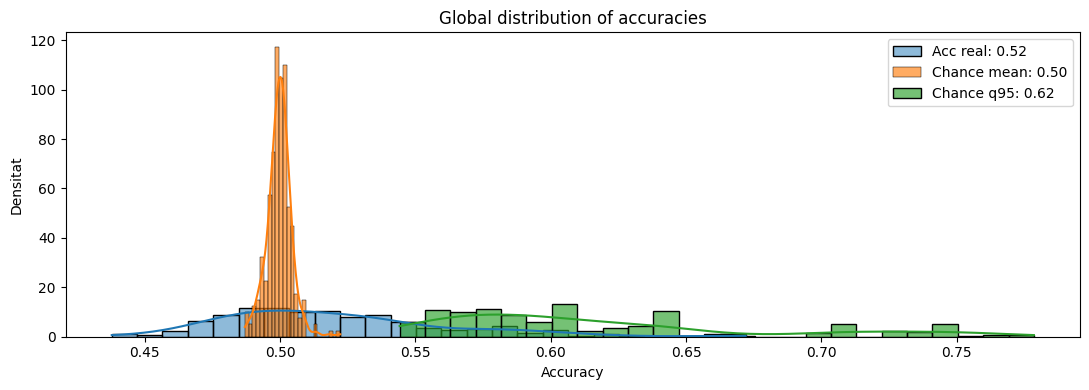

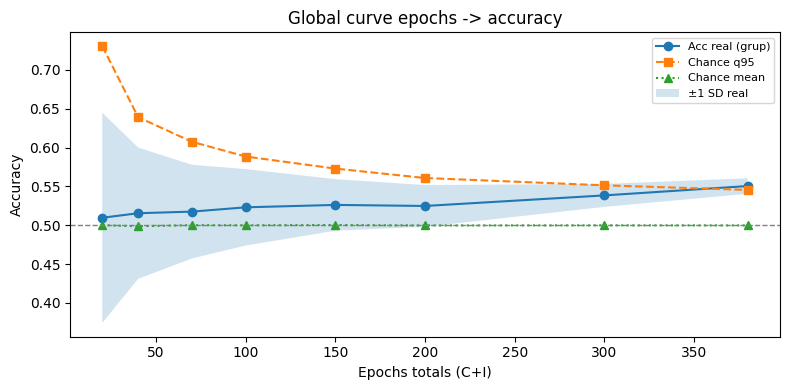

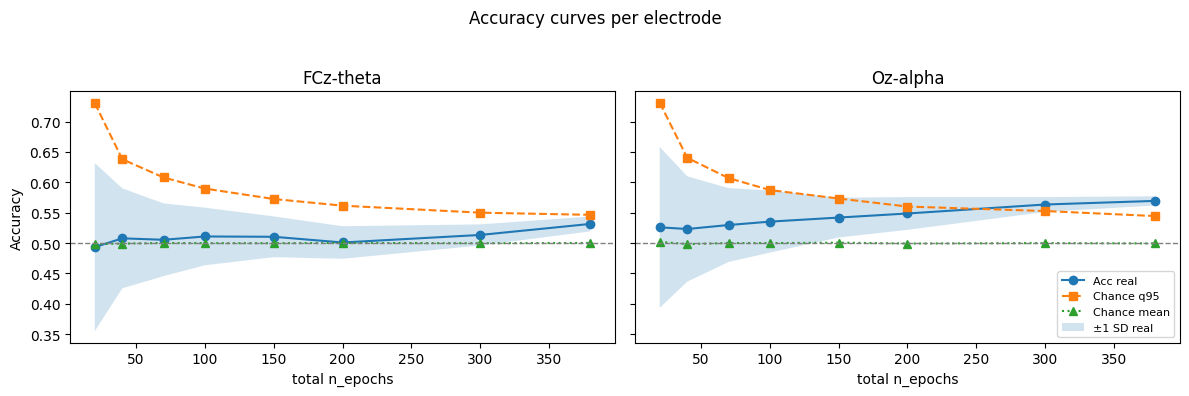

In [65]:
target_electrodes = ["FCz-theta", "Oz-alpha"]
df_two = df_epochs[df_epochs["electrode"].isin(target_electrodes)].copy()

# 7a) Distribucions globals (real vs chance)
plt.figure(figsize=(11, 4))
sns.histplot(
    df_epochs,
    x="acc_real_mean",
    color="tab:blue",
    label=f"Acc real: {df_epochs['acc_real_mean'].mean():.2f}",
    kde=True,
    stat="density",
    bins=25,
)
sns.histplot(
    df_epochs,
    x="acc_chance_mean",
    color="tab:orange",
    label=f"Chance mean: {df_epochs['acc_chance_mean'].mean():.2f}",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
sns.histplot(
    df_epochs,
    x="acc_chance_q95",
    color="tab:green",
    label=f"Chance q95: {df_epochs['acc_chance_q95'].mean():.2f}",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
plt.title("Global distribution of accuracies")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07a_distribucio_accuracies_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7b) Curve epochs -> accuracy (group)
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(8, 4))
plt.plot(grp["n_epochs_total"], grp["acc_real_mean"], "o-", label="Acc real (grup)")
plt.plot(grp["n_epochs_total"], grp["acc_chance_q95"], "s--", label="Chance q95")
plt.plot(grp["n_epochs_total"], grp["acc_chance_mean"], "^:", label="Chance mean")
plt.fill_between(
    grp["n_epochs_total"],
    grp["acc_real_mean"] - grp["acc_real_std"],
    grp["acc_real_mean"] + grp["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
plt.axhline(0.5, linestyle="--", color="gray", linewidth=1)
plt.xlabel("Epochs totals (C+I)")
plt.ylabel("Accuracy")
plt.title("Global curve epochs -> accuracy")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07b_corba_global_epochs_accuracy_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7c) Curves per electrode (only FCz-theta and Oz-alpha)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, elec in zip(axes, target_electrodes):
    d = df_two[df_two["electrode"] == elec]
    g = (
        d.groupby("n_epochs_total")
        .agg(
            acc_real_mean=("acc_real_mean", "mean"),
            acc_real_std=("acc_real_std", "mean"),
            acc_chance_q95=("acc_chance_q95", "mean"),
            acc_chance_mean=("acc_chance_mean", "mean"),
        )
        .reset_index()
    )

    ax.plot(g["n_epochs_total"], g["acc_real_mean"], "o-", label="Acc real")
    ax.plot(g["n_epochs_total"], g["acc_chance_q95"], "s--", label="Chance q95")
    ax.plot(g["n_epochs_total"], g["acc_chance_mean"], "^:", label="Chance mean")
    ax.fill_between(
        g["n_epochs_total"],
        g["acc_real_mean"] - g["acc_real_std"],
        g["acc_real_mean"] + g["acc_real_std"],
        alpha=0.2,
        label="±1 SD real",
    )
    ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
    ax.set_title(elec)
    ax.set_xlabel("total n_epochs")

axes[0].set_ylabel("Accuracy")
axes[1].legend(fontsize=8, loc="lower right")
plt.suptitle("Accuracy curves per electrode", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGURES_DIR / f"07c_corbes_accuracy_per_electrode_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

### 7d. Rate of passing q95 per electrode

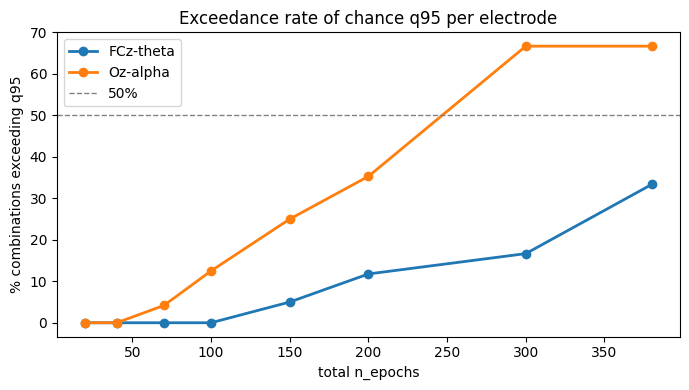

Non-informative temporal dynamics: There is only 1 temporal window. To see curves, reduce MAP_WINDOW_SEC and/or MAP_STEP_SEC and recalculate sections 5 and 6.


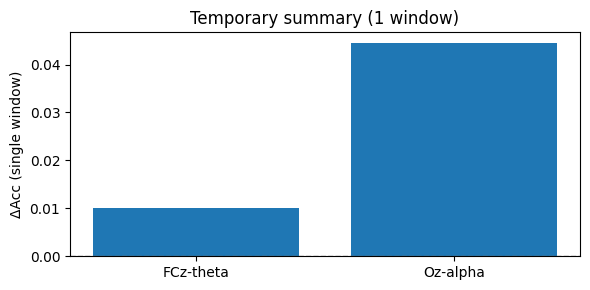


=== FINAL SUMMARY: FCz-theta vs Oz-alpha ===

FCz-theta:
  - Combinations exceeding q95: 5/142 (3.5%)
  - Average ΔAcc: 0.0062
  - Maximum Acc: 0.6001

Oz-alpha:
  - Combinations exceeding q95: 21/142 (14.8%)
  - Average ΔAcc: 0.0351
  - Maximum Acc: 0.6720



In [74]:
df_two["surpass_q95"] = (df_two["acc_real_mean"] > df_two["acc_chance_q95"]).astype(float)
surpass_tbl = (
    df_two.groupby(["electrode", "n_epochs_total"])["surpass_q95"]
    .mean()
    .unstack("electrode")
    .reindex(columns=target_electrodes)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(7, 4))
for elec in target_electrodes:
    ax.plot(
        surpass_tbl.index,
        100 * surpass_tbl[elec].values,
        marker="o",
        linewidth=2,
        label=elec,
    )
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="50%")
ax.set_xlabel("total n_epochs")
ax.set_ylabel("% combinations exceeding q95")
ax.set_title("Exceedance rate of chance q95 per electrode")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"07d_taxa_superacio_q95_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7e) Temporal dynamics (if the time×electrode map is calculated)
needed = ["window_centers", "mean_delta_map", "hit_rate_map", "ch_names"]
if all(name in globals() for name in needed):
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}

    valid_targets = [e for e in target_electrodes if e in ch_to_idx]
    if len(valid_targets) == 0:
        print("No target channels present in ch_names due to temporal dynamics.")
    elif len(window_centers) < 2:
        print(
            "Non-informative temporal dynamics: There is only 1 temporal window. "
            "To see curves, reduce MAP_WINDOW_SEC and/or MAP_STEP_SEC and recalculate sections 5 and 6."
        )
        plt.figure(figsize=(6, 3))
        bars = []
        for elec in valid_targets:
            ci = ch_to_idx[elec]
            bars.append(float(mean_delta_map[ci, 0]))
        plt.bar(valid_targets, bars)
        plt.axhline(0.0, color="gray", linestyle="--", linewidth=1)
        plt.ylabel("ΔAcc (single window)")
        plt.title("Temporary summary (1 window)")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"07e_dinamica_temporal_resum_1finestra_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        for elec in valid_targets:
            ci = ch_to_idx[elec]
            axes[0].plot(window_centers, mean_delta_map[ci], linewidth=2, label=elec)
            axes[1].plot(window_centers, hit_rate_map[ci], linewidth=2, label=elec)

        axes[0].axhline(0.0, color="gray", linestyle="--", linewidth=1)
        axes[0].set_ylabel("ΔAcc (real - chance)")
        axes[0].set_title("Temporal dynamics per electrode")
        axes[0].legend()

        axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
        axes[1].set_ylabel("Hit-rate")
        axes[1].set_xlabel("time (s)")
        axes[1].legend()

        fig.tight_layout()
        fig.savefig(FIGURES_DIR / f"07e_dinamica_temporal_per_electrode_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
        plt.show()
else:
    print("To show the temporal dynamics, run Sections 5 and 6 first.")

print("\n=== FINAL SUMMARY: FCz-theta vs Oz-alpha ===\n")
for elec in target_electrodes:
    dfe = df_two[df_two["electrode"] == elec]
    surpass = (dfe["acc_real_mean"] > dfe["acc_chance_q95"]).sum()
    total = len(dfe)
    avg_delta = dfe["delta_acc"].mean()
    max_acc = dfe["acc_real_mean"].max()
    print(f"{elec}:")
    print(f"  - Combinations exceeding q95: {surpass}/{total} ({100*surpass/total:.1f}%)")
    print(f"  - Average ΔAcc: {avg_delta:.4f}")
    print(f"  - Maximum Acc: {max_acc:.4f}")
    print()

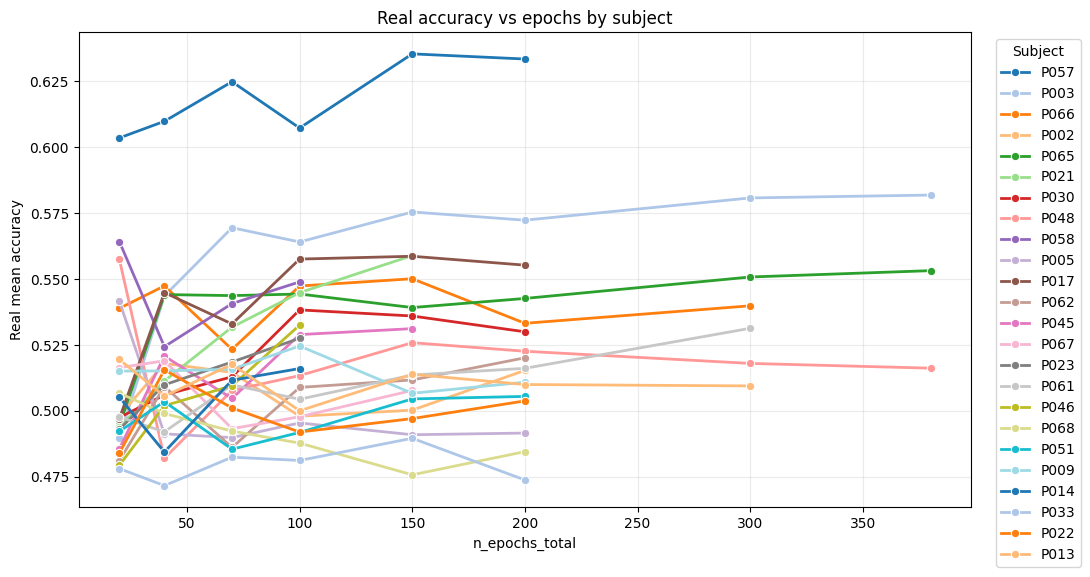

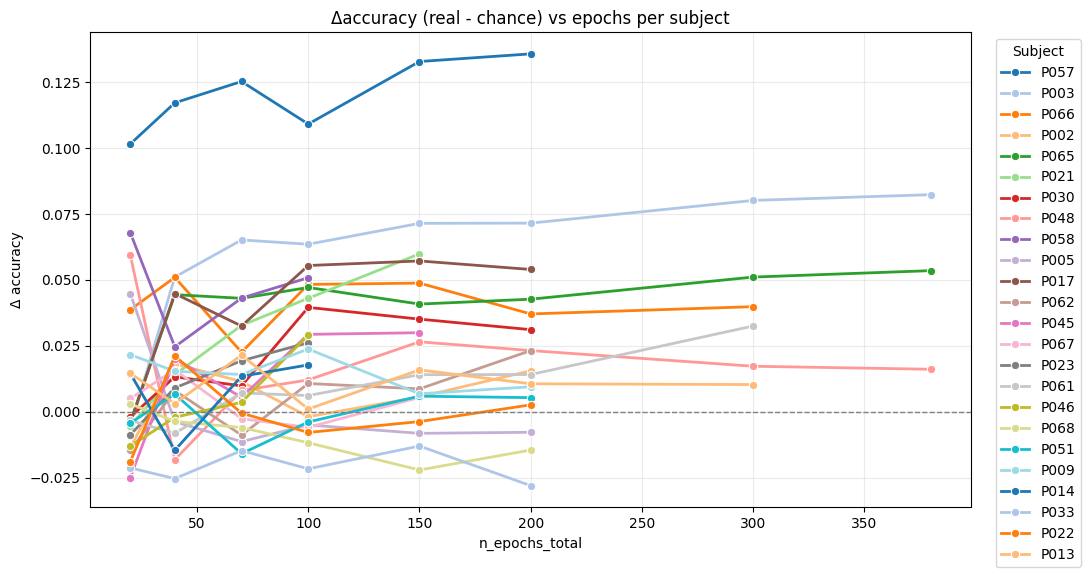

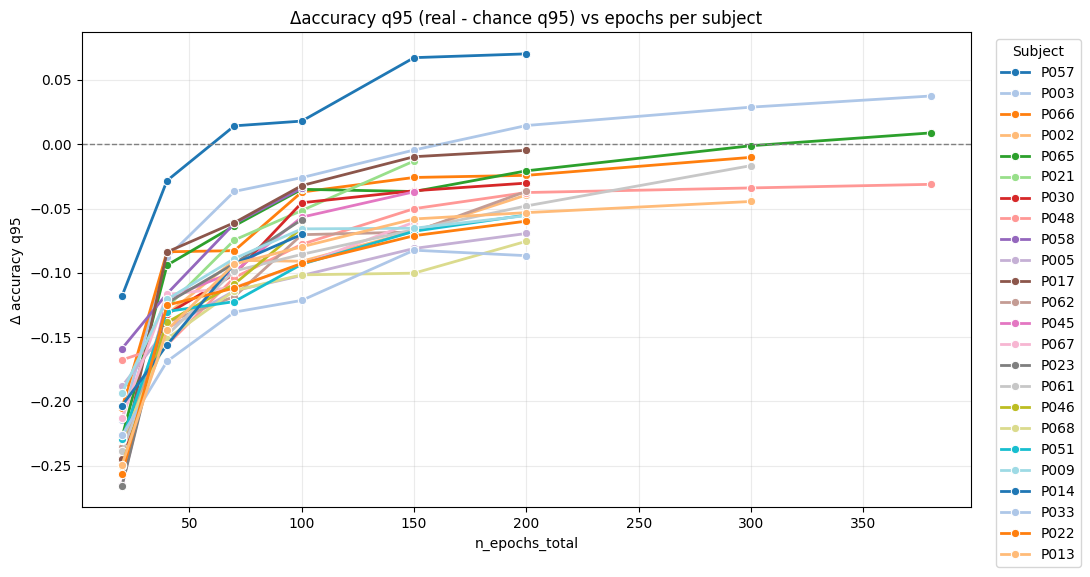

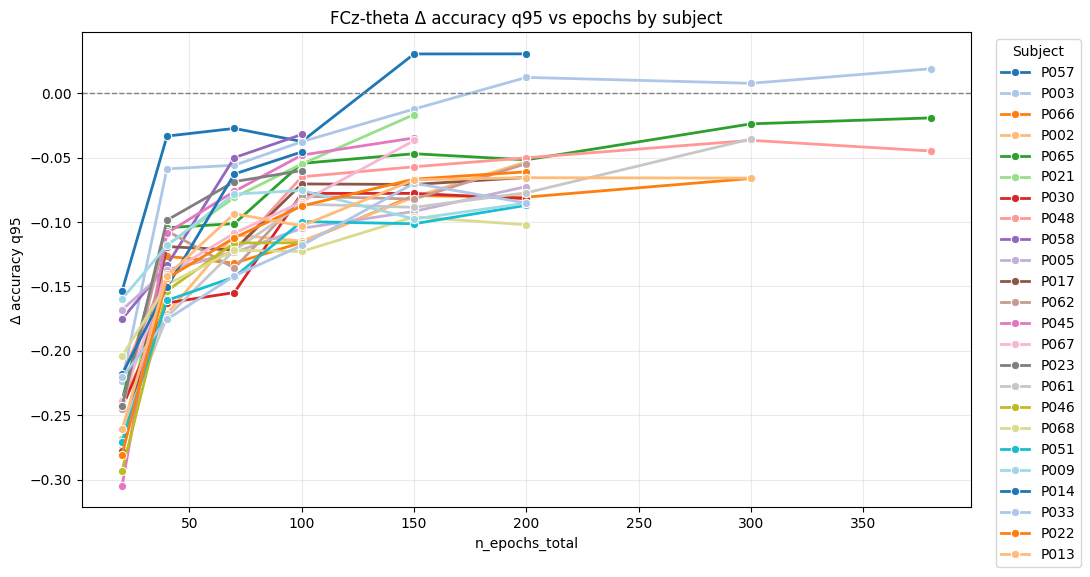

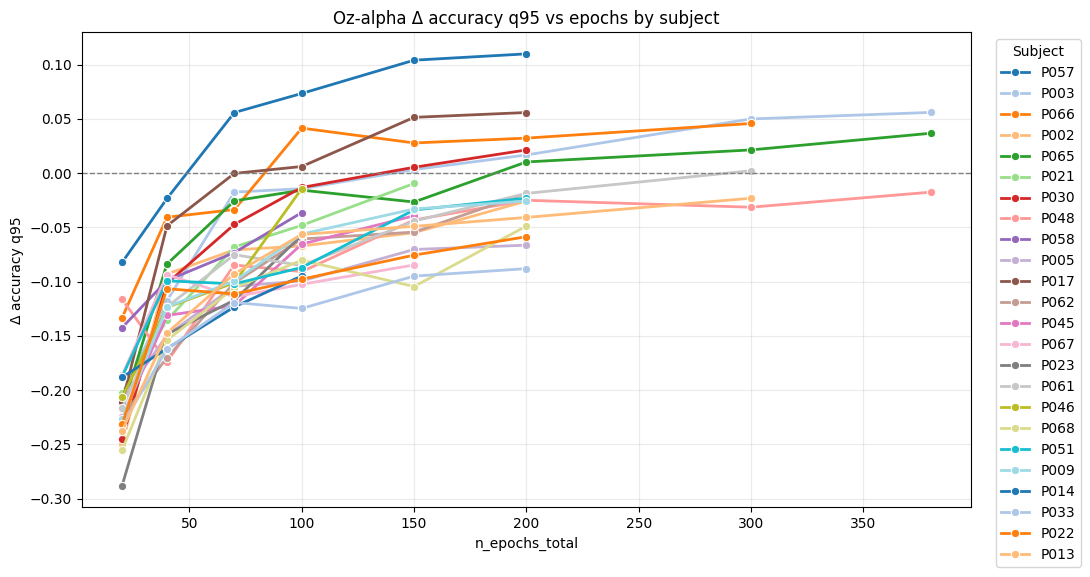

In [67]:
# Views by subject (simplified version)
subject_order = [s for s in pd.unique(subj_list) if s in df_epochs["subject"].unique()]


def agg_by_subject(metric):
    return (
        df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)[metric]
        .mean()
        .sort_values(["subject", "n_epochs_total"])
    )


def plot_subject_lines(df_plot, y_col, title, y_label, ylim=None):
    plt.figure(figsize=(11, 6))
    sns.lineplot(
        data=df_plot,
        x="n_epochs_total",
        y=y_col,
        hue="subject",
        hue_order=subject_order,
        palette="tab20",
        marker="o",
        linewidth=2,
    )
    if y_col in ["delta_acc", "delta_acc_q95"]:
        plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    plt.title(title)
    plt.xlabel("n_epochs_total")
    plt.ylabel(y_label)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.grid(alpha=0.25)
    plt.legend(title="Subject", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{y_col}_per_subject_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()


# 1) Accuracy real
plot_subject_lines(
    agg_by_subject("acc_real_mean"),
    y_col="acc_real_mean",
    title="Real accuracy vs epochs by subject",
    y_label="Real mean accuracy",
)

# 2) Delta accuracy
plot_subject_lines(
    agg_by_subject("delta_acc"),
    y_col="delta_acc",
    title="Δaccuracy (real - chance) vs epochs per subject",
    y_label="Δ accuracy",
)

# 3) Delta accuracy q95
plot_subject_lines(
    agg_by_subject("delta_acc_q95"),
    y_col="delta_acc_q95",
    title="Δaccuracy q95 (real - chance q95) vs epochs per subject",
    y_label="Δ accuracy q95",
)

# 4) Delta accuracy q95 separated by electrode (independent figures)
preferred_electrodes = ["FCz-theta", "Oz-alpha"]
plot_electrodes = [e for e in preferred_electrodes if e in df_epochs["electrode"].unique()]
if len(plot_electrodes) == 0:
    plot_electrodes = df_epochs["electrode"].dropna().unique().tolist()[:2]

df_subj_delta_q95_elec = (
    df_epochs[df_epochs["electrode"].isin(plot_electrodes)]
    .groupby(["subject", "electrode", "n_epochs_total"], as_index=False)["delta_acc_q95"]
    .mean()
    .sort_values(["electrode", "subject", "n_epochs_total"])
)

for elec in plot_electrodes:
    d = df_subj_delta_q95_elec[df_subj_delta_q95_elec["electrode"] == elec]
    plot_subject_lines(
        d,
        y_col="delta_acc_q95",
        title=f"{elec} Δ accuracy q95 vs epochs by subject",
        y_label="Δ accuracy q95",
    )

### 7g. Global model weights and spatial interpretation

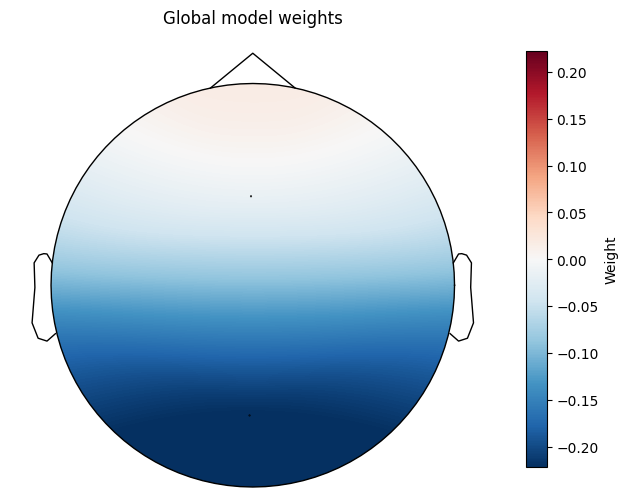

C:\Users\nils\AppData\Local\Temp\ipykernel_8232\1241376520.py:93: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights[order], y=[display_names[i] for i in order], palette="vlag", orient="h", ax=ax)


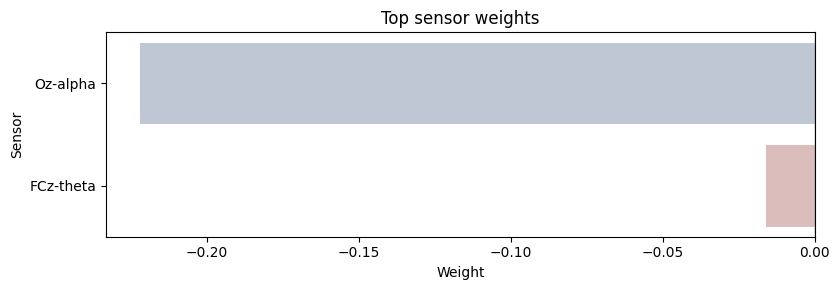

In [ ]:
def _resolve_topomap_names(n_sensors):
    # 0) Special case for chance level notebooks using TARGET_BAND_CHANNELS
    if "TARGET_BAND_CHANNELS" in globals() and len(TARGET_BAND_CHANNELS) == n_sensors:
        return [ch_name for ch_name, _ in TARGET_BAND_CHANNELS], [
            f"{ch_name}-{band}" for ch_name, band in TARGET_BAND_CHANNELS
        ]

    # 1) Best case: explicit fused channel names already available
    if "ch_names_dict" in globals() and isinstance(ch_names_dict, dict):
        for key in ("fused", "all", "common", "channels"):
            value = ch_names_dict.get(key)
            if isinstance(value, (list, tuple, np.ndarray)) and len(value) == n_sensors:
                names = [str(ch) for ch in value]
                return names, names

        # 2) Reconstruct fused names from theta+alpha lists
        theta_names = ch_names_dict.get("theta")
        alpha_names = ch_names_dict.get("alpha")
        if isinstance(theta_names, (list, tuple, np.ndarray)) and isinstance(alpha_names, (list, tuple, np.ndarray)):
            fused_names = [str(ch) for ch in theta_names] + [str(ch) for ch in alpha_names]
            if len(fused_names) == n_sensors:
                return fused_names, fused_names

        for value in ch_names_dict.values():
            if isinstance(value, (list, tuple, np.ndarray)) and len(value) == n_sensors:
                names = [str(ch) for ch in value]
                return names, names

    # 3) Reconstruct from target cluster definition (ordered theta+alpha)
    if "TARGET_BANDS_CLUSTERS" in globals() and isinstance(TARGET_BANDS_CLUSTERS, dict):
        ordered = []
        for band in ("theta", "alpha"):
            if band in TARGET_BANDS_CLUSTERS:
                ordered.extend([str(ch) for ch in TARGET_BANDS_CLUSTERS[band]])
        if len(ordered) == n_sensors:
            return ordered, ordered

    if "ch_names" in globals() and isinstance(ch_names, (list, tuple, np.ndarray)) and len(ch_names) == n_sensors:
        names = [str(ch) for ch in ch_names]
        return names, names

    if (
        "target_electrodes" in globals()
        and isinstance(target_electrodes, (list, tuple, np.ndarray))
        and len(target_electrodes) == n_sensors
    ):
        names = [str(ch) for ch in target_electrodes]
        return names, names

    fallback = [f"ch{i}" for i in range(n_sensors)]
    return fallback, fallback


def _weights_from_classifier(model, n_sensors):
    final_estimator = model.steps[-1][1] if hasattr(model, "steps") else model
    coef = np.asarray(getattr(final_estimator, "coef_", np.array([]))).ravel()
    if coef.size == 0:
        return np.zeros(n_sensors, dtype=float)
    if coef.size == n_sensors:
        return coef.astype(float)
    tri_size = n_sensors * (n_sensors + 1) // 2
    if coef.size == tri_size:
        weights = np.zeros(n_sensors, dtype=float)
        k = 0
        for i in range(n_sensors):
            for j in range(i, n_sensors):
                value = float(abs(coef[k]))
                if i == j:
                    weights[i] += value
                else:
                    weights[i] += 0.5 * value
                    weights[j] += 0.5 * value
                k += 1
        return weights
    return np.abs(np.resize(coef, n_sensors)).astype(float)


X_feat = np.mean(np.abs(hilbert(np.asarray(X), axis=-1)), axis=-1)
if X_feat.ndim == 1:
    X_feat = X_feat[:, None]

model = experiment.model_factory.make()
model.fit(X_feat, y)

sensor_names, display_names = _resolve_topomap_names(X_feat.shape[1])
if len(sensor_names) != X_feat.shape[1]:
    sensor_names = [f"ch{i}" for i in range(X_feat.shape[1])]
    display_names = sensor_names

weights = _weights_from_classifier(model, len(sensor_names))
weights = np.nan_to_num(weights.astype(float), nan=0.0)

info = mne.create_info(sensor_names, sfreq=1.0, ch_types="eeg")
try:
    info.set_montage("standard_1020", on_missing="ignore")
except Exception:
    pass

topomap_title = "Global model weights"
fig, ax = plt.subplots(figsize=(6.5, 5.5))
try:
    im, _ = mne.viz.plot_topomap(weights, info, axes=ax, show=False, cmap="RdBu_r", contours=0)
    fig.colorbar(im, ax=ax, shrink=0.8, label="Weight")
    ax.set_title(topomap_title)
except Exception:
    order = np.argsort(np.abs(weights))[::-1]
    ax.bar(np.arange(len(order)), weights[order], color=["tab:red" if weights[i] >= 0 else "tab:blue" for i in order])
    ax.set_xticks(np.arange(len(order)))
    ax.set_xticklabels([display_names[i] for i in order], rotation=45, ha="right")
    ax.set_ylabel("Weight")
    ax.set_title(topomap_title)
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07g_model_weights_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
plt.show()

top_n = min(8, len(weights))
order = np.argsort(np.abs(weights))[::-1][:top_n]
fig, ax = plt.subplots(figsize=(8.5, max(3.0, 0.45 * top_n + 1.0)))
sns.barplot(x=weights[order], y=[display_names[i] for i in order], palette="vlag", orient="h", ax=ax)
ax.axvline(0.0, color="0.5", linewidth=1)
ax.set_title("Top sensor weights")
ax.set_xlabel("Weight")
ax.set_ylabel("Sensor")
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07g_model_weights_bar_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. ROC/PR Curves


Classification Report for Subject P057 (FCz-theta):
              precision    recall  f1-score   support

           0       0.56      0.59      0.57        98
           1       0.58      0.55      0.57       102

    accuracy                           0.57       200
   macro avg       0.57      0.57      0.57       200
weighted avg       0.57      0.57      0.57       200


Classification Report for Subject P057 (Oz-alpha):
              precision    recall  f1-score   support

           0       0.63      0.71      0.67        98
           1       0.69      0.60      0.64       102

    accuracy                           0.66       200
   macro avg       0.66      0.66      0.65       200
weighted avg       0.66      0.66      0.65       200



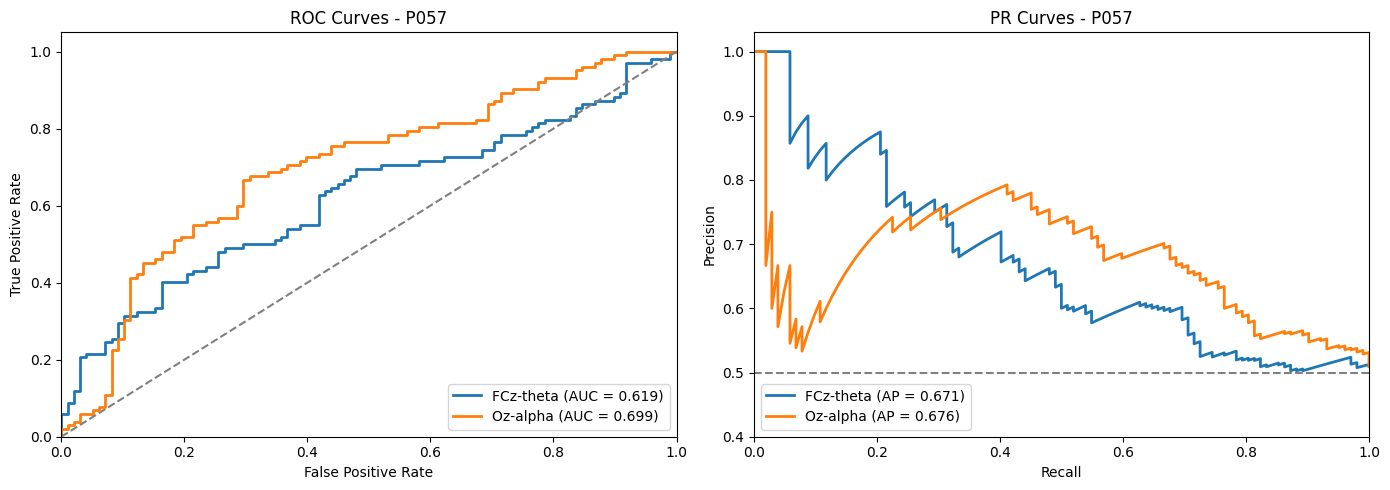

Saved final models and plots for P057

Classification Report for Subject P003 (FCz-theta):
              precision    recall  f1-score   support

           0       0.57      0.52      0.54       158
           1       0.57      0.62      0.59       160

    accuracy                           0.57       318
   macro avg       0.57      0.57      0.57       318
weighted avg       0.57      0.57      0.57       318


Classification Report for Subject P003 (Oz-alpha):
              precision    recall  f1-score   support

           0       0.61      0.56      0.58       158
           1       0.60      0.65      0.62       160

    accuracy                           0.60       318
   macro avg       0.60      0.60      0.60       318
weighted avg       0.60      0.60      0.60       318


Classification Report for Subject P066 (FCz-theta):
              precision    recall  f1-score   support

           0       0.44      0.20      0.27       140
           1       0.47      0.73      0.

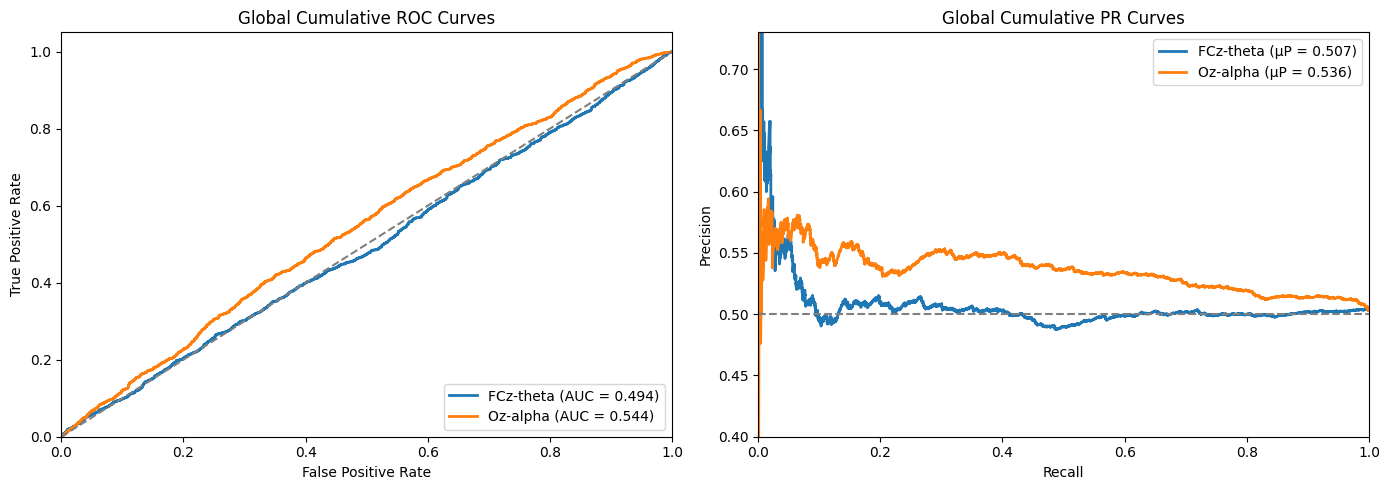

Saved global cumulative ROC/PR plots.


In [86]:
oof_save_dict = {}
subject_ids = pd.unique(subj_list).tolist()

# Define MODELS_DIR
MODELS_DIR = CACHE_DIR / "weights"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

X = X_dict if "X_dict" in globals() else (X if "X" in globals() else None)
is_riemann = isinstance(X, dict)

# We only plot ROC/PR curves for one target subject and the global cumulative across all subjects
plot_subj_target = "P057"
if plot_subj_target not in subject_ids:
    plot_subj_target = subject_ids[0] if subject_ids else None

for subj_name in subject_ids:
    subj_mask = subj_list == subj_name
    y_s = y[subj_mask]

    if len(np.unique(y_s)) < 2:
        continue

    should_plot = subj_name == plot_subj_target
    if should_plot:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Save true labels
    oof_save_dict[f"{subj_name}_y_true"] = y_s

    labels_to_eval = CHANNEL_MODE if is_riemann else ch_names

    for ch_idx, label in enumerate(labels_to_eval):
        # Extract features
        if is_riemann:
            # X is X_dict
            X_feat = X[label][subj_mask]
        else:
            # X is X_ndarray
            Xs_ch = X[subj_mask, ch_idx, :]
            extractor = HilbertMeanEnvelope()
            X_feat = extractor.transform(Xs_ch)
            if X_feat.ndim == 1:
                X_feat = X_feat[:, None]

        n_splits = choose_n_splits(y_s, max_splits=5)
        splits = temporal_stratified_splits(y_s, n_splits)

        # Out-of-fold prediction array
        oof_probs = np.full(len(y_s), np.nan)

        for tr, te in splits:
            model = experiment.model_factory.make()
            model.fit(X_feat[tr], y_s[tr])
            # Predict probabilities
            probs = model.predict_proba(X_feat[te])[:, 1]
            oof_probs[te] = probs

        valid_mask = ~np.isnan(oof_probs)
        y_valid = y_s[valid_mask]
        preds_valid = oof_probs[valid_mask]

        oof_save_dict[f"{subj_name}_{label}_prob"] = oof_probs

        y_pred = (preds_valid >= 0.5).astype(int)
        print(f"\nClassification Report for Subject {subj_name} ({label}):")
        print(classification_report(y_valid, y_pred))

        if should_plot:
            # Compute ROC
            fpr, tpr, _ = roc_curve(y_valid, preds_valid)
            roc_auc = auc(fpr, tpr)
            axes[0].plot(fpr, tpr, label=f"{label} (AUC = {roc_auc:.3f})", linewidth=2)

            # Compute PR
            precision, recall, _ = precision_recall_curve(y_valid, preds_valid)
            ap = average_precision_score(y_valid, preds_valid)
            axes[1].plot(recall, precision, label=f"{label} (AP = {ap:.3f})", linewidth=2)

        # Train final model on ALL data for this subject/channel
        final_model = experiment.model_factory.make()
        final_model.fit(X_feat, y_s)

        # Save model
        model_filename = MODELS_DIR / f"final_model_{TASK_TAG}_{subj_name}_{label}.joblib"
        joblib.dump(final_model, model_filename)

    if should_plot:
        # Formatting plots
        axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--")
        axes[0].set_xlim([0.0, 1.0])
        axes[0].set_ylim([0.0, 1.05])
        axes[0].set_xlabel("False Positive Rate")
        axes[0].set_ylabel("True Positive Rate")
        axes[0].set_title(f"ROC Curves - {subj_name}")
        axes[0].legend(loc="lower right")

        axes[1].axhline(0.5, color="grey", linestyle="--")
        axes[1].set_xlim([0.0, 1.0])
        axes[1].set_ylim([0.4, 1.03])
        axes[1].set_xlabel("Recall")
        axes[1].set_ylabel("Precision")
        axes[1].set_title(f"PR Curves - {subj_name}")
        axes[1].legend(loc="lower left")

        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"roc_pr_curves_{subj_name}.png", dpi=150)
        plt.show()
        print(f"Saved final models and plots for {subj_name}")

# Save out-of-fold predictions for future comparison
np.savez_compressed(CACHE_DIR / f"oof_predictions_{TASK_TAG}.npz", **oof_save_dict)
print(f"Saved out-of-fold predictions to: {CACHE_DIR / f'oof_predictions_{TASK_TAG}.npz'}")

# Aggregated classification report and global cumulative ROC/PR curves across all subjects
fig_global, axes_global = plt.subplots(1, 2, figsize=(14, 5))

for label in labels_to_eval:
    y_true_lbl = []
    y_pred_lbl = []
    y_prob_lbl = []
    for subj_name in subject_ids:
        if f"{subj_name}_y_true" in oof_save_dict and f"{subj_name}_{label}_prob" in oof_save_dict:
            y_s = oof_save_dict[f"{subj_name}_y_true"]
            probs = oof_save_dict[f"{subj_name}_{label}_prob"]
            valid = ~np.isnan(probs)
            y_true_lbl.extend(y_s[valid])
            y_prob_lbl.extend(probs[valid])
            y_pred_lbl.extend((probs[valid] >= 0.5).astype(int))

    if y_true_lbl:
        print("\n" + "=" * 50)
        print(f"AGGREGATED CLASSIFICATION REPORT FOR LABEL: {label}")
        print("=" * 50)
        print(classification_report(y_true_lbl, y_pred_lbl))
        print("=" * 50 + "\n")

        # Compute global ROC
        fpr, tpr, _ = roc_curve(y_true_lbl, y_prob_lbl)
        roc_auc = auc(fpr, tpr)
        axes_global[0].plot(fpr, tpr, label=f"{label} (AUC = {roc_auc:.3f})", linewidth=2)

        # Compute global PR
        precision, recall, _ = precision_recall_curve(y_true_lbl, y_prob_lbl)
        ap = average_precision_score(y_true_lbl, y_prob_lbl)
        axes_global[1].plot(recall, precision, label=f"{label} (μP = {ap:.3f})", linewidth=2)

# Formatting global plots
axes_global[0].plot([0, 1], [0, 1], color="grey", linestyle="--")
axes_global[0].set_xlim([0.0, 1.0])
axes_global[0].set_ylim([0.0, 1.05])
axes_global[0].set_xlabel("False Positive Rate")
axes_global[0].set_ylabel("True Positive Rate")
axes_global[0].set_title("Global Cumulative ROC Curves")
axes_global[0].legend(loc="lower right")

axes_global[1].axhline(0.5, color="grey", linestyle="--")
axes_global[1].set_xlim([0.0, 1.0])
axes_global[1].set_ylim([0.4, 0.73])
axes_global[1].set_xlabel("Recall")
axes_global[1].set_ylabel("Precision")
axes_global[1].set_title("Global Cumulative PR Curves")
axes_global[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_pr_curves_global.png", dpi=150)
plt.show()
print("Saved global cumulative ROC/PR plots.")